In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("img2.jpeg")

if image is None:
    raise FileNotFoundError("img2.jpeg not found")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

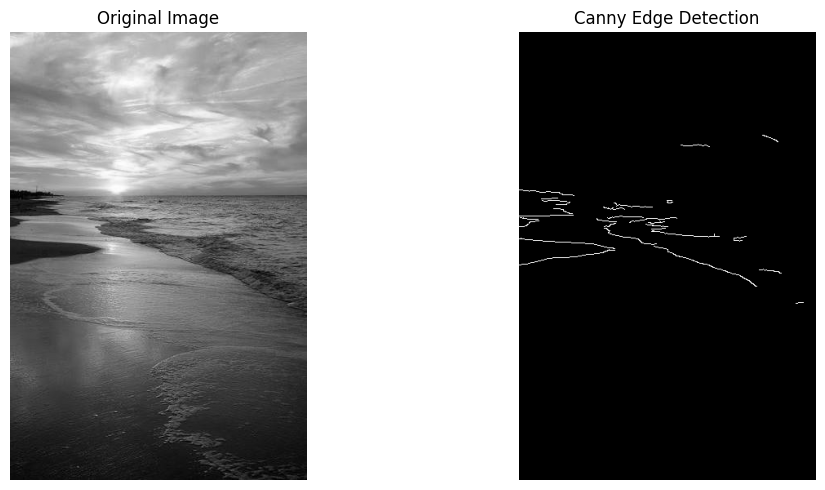

In [13]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 100, 200)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

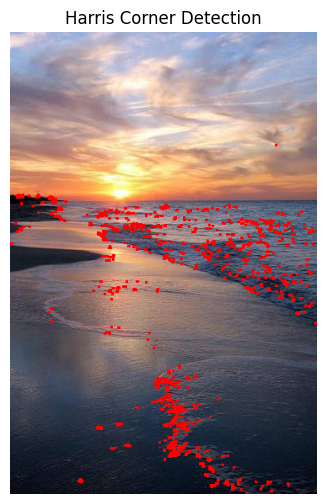

In [14]:
gray_float = np.float32(gray)
corners = cv2.cornerHarris(gray_float, 2, 3, 0.04)
corners = cv2.dilate(corners, None)

result = image.copy()
result[corners > 0.01 * corners.max()] = [0, 0, 255]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Harris Corner Detection")
plt.axis("off")
plt.show()

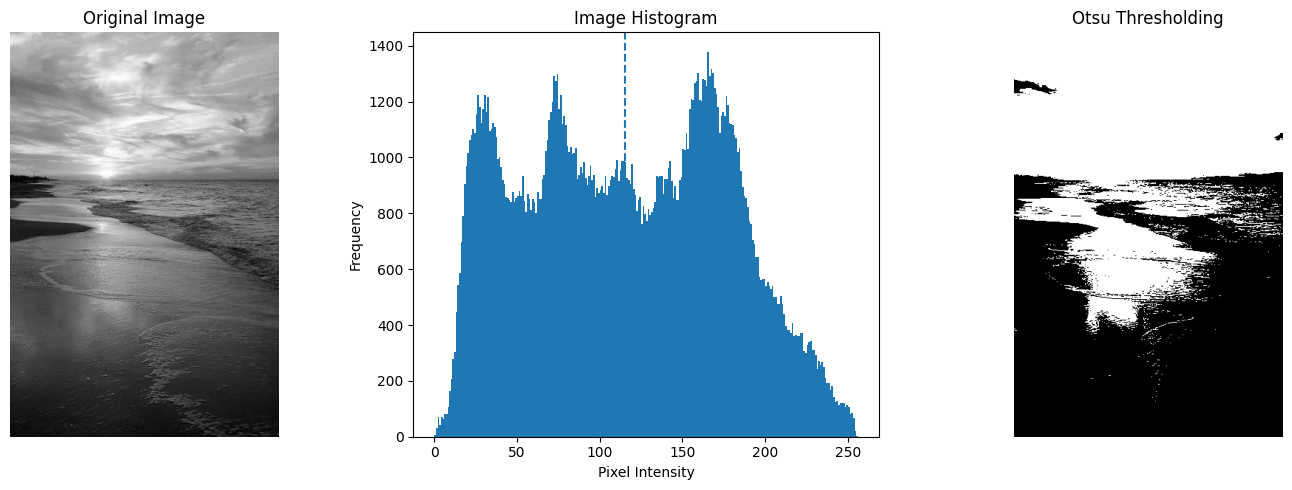

Otsu Threshold: 115.0


In [15]:
threshold_value, otsu = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.axvline(threshold_value, linestyle="--")
plt.title("Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 3, 3)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Otsu Threshold:", threshold_value)

Otsu automatically selects the best threshold to separate the image into foreground and background.